# Fig 9 — NOB RBC (glycerol): reference datasets + this work

$Ra=10^6$, $Pr=2547$, $\Gamma=6$: $\Delta(\Theta_c-\Theta_m)$ vs $\Delta T$

Plots each CSV in this directory by name:
- `Horm.csv` — scatter
- `PaScaL_TCS.csv` — scatter
- `zhang.csv` — line with markers (sorted by $\Delta T$; the raw file has a few points appended out of x-order)

Also overlays this project's own MPM-STD_C GPU results (Report/34,35):
- $\Delta T=20$K pre-fix (128³, cell-centered NOB buoyancy): $\Theta_c=0.0404$
- $\Delta T=20$K post-fix (256³, face-interp buoyancy, E18+E19 plateau): $\Theta_c=0.0647$
- $\Delta T=40$K pre-fix (128³, cell-centered NOB buoyancy): $\Theta_c=0.0685$
- $\Delta T=40$K post-fix (256³, face-interp buoyancy, E22, restart+settle(300k)+measure(420k), plateaued): $\Theta_c=0.1279$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os

DATA_DIR = os.getcwd()

def load_csv(name):
    dt, y = [], []
    with open(os.path.join(DATA_DIR, name)) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            a, b = line.split(',')
            dt.append(float(a)); y.append(float(b))
    return np.array(dt), np.array(y)

horm_dt, horm_y     = load_csv('Horm.csv')
pascal_dt, pascal_y = load_csv('PaScaL_TCS.csv')
zhang_dt, zhang_y   = load_csv('zhang.csv')

# zhang.csv has a few points appended out of x-order -- sort for a clean line
zorder = np.argsort(zhang_dt)
zhang_dt, zhang_y = zhang_dt[zorder], zhang_y[zorder]

print(f'Horm.csv: {len(horm_dt)} points')
print(f'PaScaL_TCS.csv: {len(pascal_dt)} points')
print(f'zhang.csv: {len(zhang_dt)} points')

Horm.csv: 7 points
PaScaL_TCS.csv: 3 points
zhang.csv: 47 points


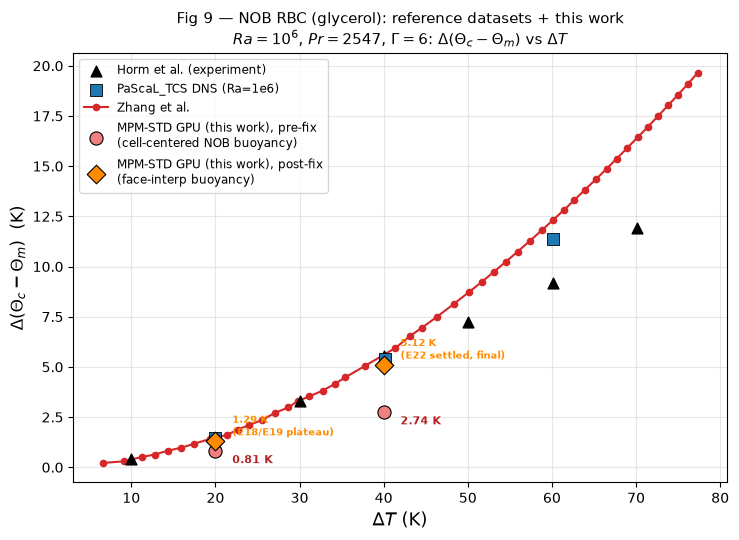

In [2]:
# this project's own MPM-STD_C GPU results (Report/34, 35)
# (DeltaT, Theta_c, label_suffix)
MINE_PREFIX = [
    (20.0, 0.0404, '128³, ~500k steps'),
    (40.0, 0.0685, '128³, ~350k steps'),
]
MINE_POSTFIX = [
    (20.0, 0.0647, 'E18/E19 plateau'),
    (40.0, 0.1279, 'E22 settled, final'),
]
mine_prefix_dt  = np.array([p[0] for p in MINE_PREFIX])
mine_prefix_y   = np.array([p[0] * p[1] for p in MINE_PREFIX])
mine_postfix_dt = np.array([p[0] for p in MINE_POSTFIX])
mine_postfix_y  = np.array([p[0] * p[1] for p in MINE_POSTFIX])

fig, ax = plt.subplots(figsize=(7.5, 5.5))

ax.scatter(horm_dt, horm_y, marker='^', s=60, color='black',
           edgecolors='k', zorder=4, label='Horm et al. (experiment)')
ax.scatter(pascal_dt, pascal_y, marker='s', s=70, color='tab:blue',
           edgecolors='k', linewidths=0.6, zorder=5, label='PaScaL_TCS DNS (Ra=1e6)')
ax.plot(zhang_dt, zhang_y, marker='o', markersize=4.5, linewidth=1.5,
        color='tab:red', zorder=3, label='Zhang et al.')

ax.scatter(mine_prefix_dt, mine_prefix_y, marker='o', s=90, color='lightcoral',
           edgecolors='k', linewidths=0.8, zorder=6,
           label='MPM-STD GPU (this work), pre-fix\n(cell-centered NOB buoyancy)')
ax.scatter(mine_postfix_dt, mine_postfix_y, marker='D', s=90, color='darkorange',
           edgecolors='k', linewidths=0.8, zorder=7,
           label='MPM-STD GPU (this work), post-fix\n(face-interp buoyancy)')
for dt, y, (_, _, note) in zip(mine_prefix_dt, mine_prefix_y, MINE_PREFIX):
    ax.annotate(f'{y:.2f} K', xy=(dt, y), xytext=(dt+2, y-0.6),
                fontsize=8, color='firebrick', fontweight='bold')
for dt, y, (_, _, note) in zip(mine_postfix_dt, mine_postfix_y, MINE_POSTFIX):
    ax.annotate(f'{y:.2f} K\n({note})', xy=(dt, y), xytext=(dt+2, y+0.3),
                fontsize=7.5, color='darkorange', fontweight='bold')

ax.set_xlabel(r'$\Delta T$ (K)', fontsize=13)
ax.set_ylabel(r'$\Delta(\Theta_c - \Theta_m)$  (K)', fontsize=12)
ax.set_title('Fig 9 — NOB RBC (glycerol): reference datasets + this work\n'
             r'$Ra=10^6$, $Pr=2547$, $\Gamma=6$: $\Delta(\Theta_c-\Theta_m)$ vs $\Delta T$',
             fontsize=11)
ax.legend(fontsize=8.5, loc='upper left')
ax.grid(True, alpha=0.3)
ax.tick_params(labelsize=10)

plt.tight_layout()
plt.savefig('fig9_datasets.png', dpi=150, bbox_inches='tight')
plt.show()